In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [18]:
print(df.shape)
df.info()
print(df.isnull().sum().sum())

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


In [19]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())
df.dropna(subset=["TotalCharges"], inplace=True)
df.drop("customerID", axis=1, inplace=True)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df.to_csv("data/cleaned_churn.csv", index=False)
print(df.shape)

Missing TotalCharges: 11
(7032, 20)


C:\Users\pc\AppData\Local\Temp\ipykernel_7808\225160098.py:3: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=["TotalCharges"], inplace=True)
C:\Users\pc\AppData\Local\Temp\ipykernel_7808\225160098.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop("customerID", axis=1, inplace=True)


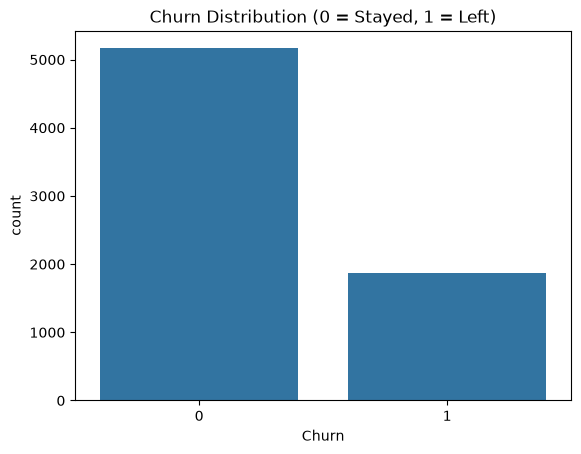

In [20]:
sns.countplot(x="Churn", data=df)
plt.title("Churn Distribution (0 = Stayed, 1 = Left)")
plt.savefig("images/churn_distribution.png")
plt.show()

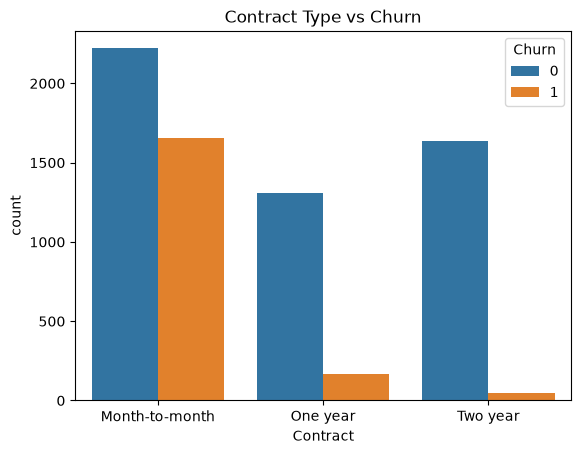

In [21]:
sns.countplot(x="Contract", hue="Churn", data=df)
plt.title("Contract Type vs Churn")
plt.savefig("images/contract_vs_churn.png")
plt.show()

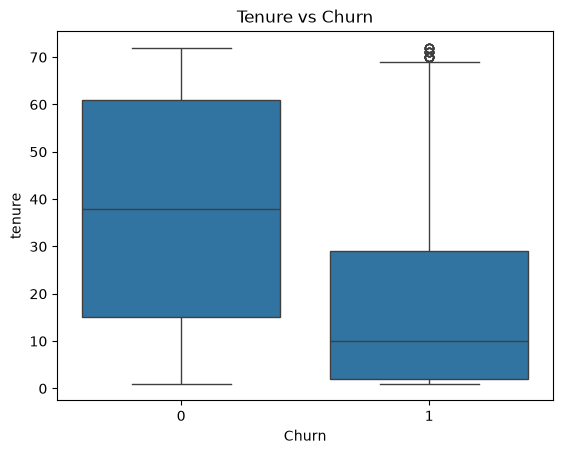

In [22]:
sns.boxplot(x="Churn", y="tenure", data=df)
plt.title("Tenure vs Churn")
plt.savefig("images/tenure_vs_churn.png")
plt.show()

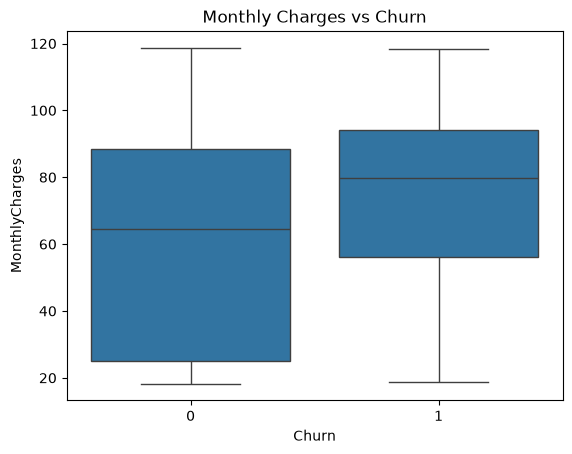

In [23]:
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Monthly Charges vs Churn")
plt.savefig("images/monthly_vs_churn.png")
plt.show()

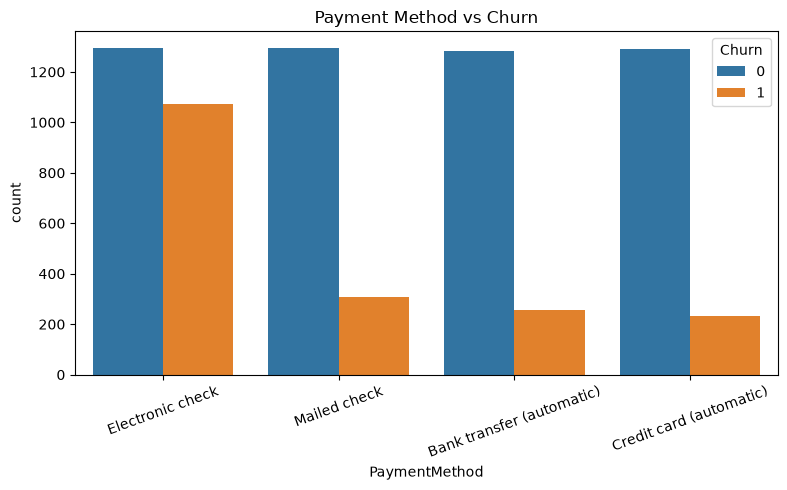

In [24]:
plt.figure(figsize=(8,5))
sns.countplot(x="PaymentMethod", hue="Churn", data=df)
plt.xticks(rotation=20)
plt.title("Payment Method vs Churn")
plt.tight_layout()
plt.savefig("images/payment_vs_churn.png")
plt.show()

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df_model = pd.get_dummies(df, drop_first=True)
X = df_model.drop("Churn", axis=1)
y = df_model["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)


In [26]:
lr = LogisticRegression(max_iter=3000).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train, y_train)

for name, m in [("Logistic Regression", lr), ("Random Forest", rf)]:
    pred = m.predict(X_test)
    print("====", name, "====")
    print("Accuracy:", round(accuracy_score(y_test, pred), 4))
    print(classification_report(y_test, pred))
    print(confusion_matrix(y_test, pred))
    

==== Logistic Regression ====
Accuracy: 0.8045
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.58      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407

[[916 117]
 [158 216]]
==== Random Forest ====
Accuracy: 0.7868
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

[[917 116]
 [184 190]]


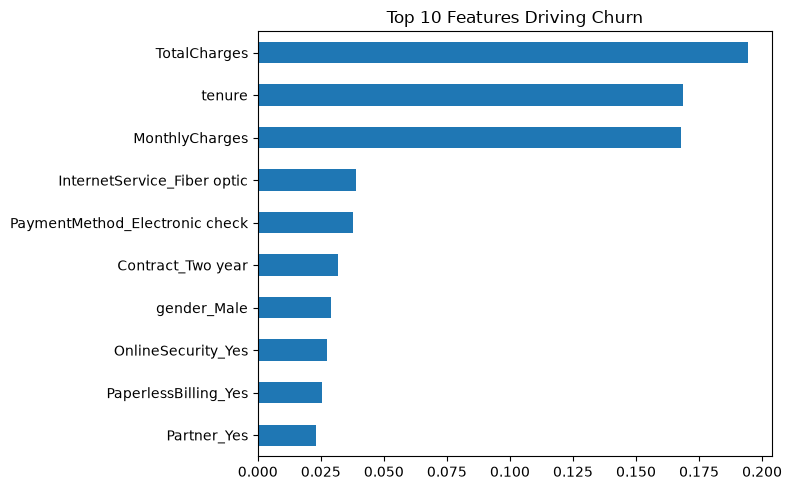

In [27]:
imp = pd.Series(rf.feature_importances_, index=X.columns).nlargest(10)
imp.sort_values().plot(kind="barh", figsize=(8,5))
plt.title("Top 10 Features Driving Churn")
plt.tight_layout()
plt.savefig("images/feature_importance.png")
plt.show()


In [28]:
print("Churn rate:", round(df["Churn"].mean()*100, 2), "%")
print(df.groupby("Contract")["Churn"].mean().round(3))
print(df.groupby("InternetService")["Churn"].mean().round(3))
print(df.groupby("PaymentMethod")["Churn"].mean().round(3))
print(df.groupby("Churn")[["tenure","MonthlyCharges"]].mean().round(2))

Churn rate: 26.58 %
Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64
InternetService
DSL            0.190
Fiber optic    0.419
No             0.074
Name: Churn, dtype: float64
PaymentMethod
Bank transfer (automatic)    0.167
Credit card (automatic)      0.153
Electronic check             0.453
Mailed check                 0.192
Name: Churn, dtype: float64
       tenure  MonthlyCharges
Churn                        
0       37.65           61.31
1       17.98           74.44


In [29]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

df = pd.read_csv("data/cleaned_churn.csv")
print(df.shape)
df.head()

(7032, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [30]:
df_model = df.copy()

# customerID prediction ki avasaram ledu
if "customerID" in df_model.columns:
    df_model = df_model.drop("customerID", axis=1)

# Target: Yes/No ni 1/0 ki marchandi
df_model["Churn"] = df_model["Churn"].map({"Yes": 1, "No": 0})

# Migata text columns ki one-hot encoding
df_model = pd.get_dummies(df_model, drop_first=True)

print(df_model.shape)
df_model.head()

(7032, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,NaN,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,NaN,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,NaN,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,NaN,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,NaN,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


In [31]:
print(df["Churn"].unique())
print(df["Churn"].dtype)

[0 1]
int64


In [32]:

df_model = df.copy()

if "customerID" in df_model.columns:
    df_model = df_model.drop("customerID", axis=1)

# Churn Yes/No aina, 0/1 aina handle chestundi
if df_model["Churn"].dtype == "object":
    df_model["Churn"] = df_model["Churn"].str.strip().map({"Yes": 1, "No": 0})

df_model = pd.get_dummies(df_model, drop_first=True)

print(df_model["Churn"].isna().sum())   # 0 ravali
print(df_model.shape)

0
(7032, 31)


In [33]:
print(df_model.isna().sum().sum())
df_model = df_model.dropna()

0


In [34]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

results_df = pd.DataFrame(results).round(3)
results_df

c:\Users\pc\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.803,0.646,0.575,0.608,0.837
1,Random Forest,0.787,0.621,0.508,0.559,0.818


In [35]:
import joblib, os
os.makedirs("models", exist_ok=True)
joblib.dump(models["Logistic Regression"], "models/churn_model.pkl")

['models/churn_model.pkl']

In [36]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

results_df = pd.DataFrame(results).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.804,0.648,0.575,0.609,0.836
1,Random Forest,0.787,0.621,0.508,0.559,0.818


In [37]:
import joblib, os
os.makedirs("models", exist_ok=True)
joblib.dump(models["Logistic Regression"], "models/churn_model.pkl")

['models/churn_model.pkl']

In [38]:
import joblib

model = joblib.load("models/churn_model.pkl")

# Test data lo nundi oka customer teeskundam
sample = X_test.iloc[[0]]

prob = model.predict_proba(sample)[0][1]
pred = model.predict(sample)[0]

print(f"Churn probability: {prob:.2%}")
print("Prediction:", "Churn avthadu" if pred == 1 else "Churn avvadu")
print("Nijamaina value:", "Churn" if y_test.iloc[0] == 1 else "No churn")

Churn probability: 1.71%
Prediction: Churn avvadu
Nijamaina value: No churn


In [39]:
test_results = X_test.copy()
test_results["Churn_Probability"] = model.predict_proba(X_test)[:, 1]
test_results["Actual"] = y_test.values

top_risk = test_results.sort_values("Churn_Probability", ascending=False).head(10)
top_risk[["Churn_Probability", "Actual"]]

,Churn_Probability,Actual
3380,0.847428,1
3159,0.846212,0
2631,0.828196,1
4585,0.822446,1
582,0.817107,1
2797,0.815147,1
3727,0.813745,1
933,0.811263,1
6240,0.796931,1
5213,0.795470,0


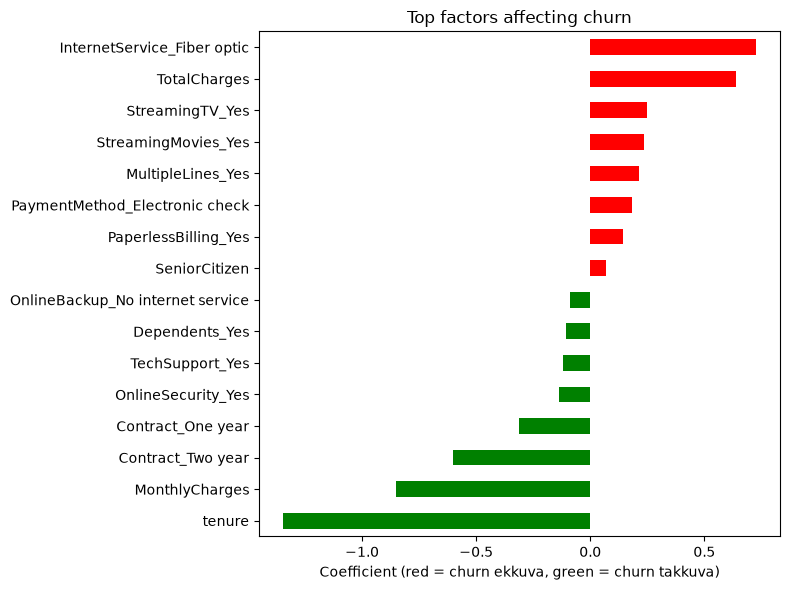

In [40]:
import matplotlib.pyplot as plt

coefs = model.named_steps["logisticregression"].coef_[0]
importance = pd.Series(coefs, index=X.columns).sort_values()

top = pd.concat([importance.head(8), importance.tail(8)])

plt.figure(figsize=(8, 6))
top.plot(kind="barh", color=["green" if v < 0 else "red" for v in top])
plt.title("Top factors affecting churn")
plt.xlabel("Coefficient (red = churn ekkuva, green = churn takkuva)")
plt.tight_layout()
plt.savefig("images/model_feature_importance.png", dpi=150)
plt.show()

In [41]:
lr_bal = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, class_weight="balanced")
)
lr_bal.fit(X_train, y_train)

pred = lr_bal.predict(X_test)
prob = lr_bal.predict_proba(X_test)[:, 1]

pd.DataFrame([{
    "Model": "Logistic Regression (balanced)",
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred),
    "Recall": recall_score(y_test, pred),
    "F1": f1_score(y_test, pred),
    "ROC-AUC": roc_auc_score(y_test, prob),
}]).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression (balanced),0.726,0.491,0.797,0.608,0.835


In [42]:
joblib.dump(lr_bal, "models/churn_model_balanced.pkl")

['models/churn_model_balanced.pkl']